# Riesgo académico · Asistente UNAB 360

El objetivo es anticipar qué estudiantes podrían necesitar apoyo durante un semestre. La prueba reconstruye lo que se sabía al cierre del periodo anterior y usa el siguiente periodo cerrado como resultado observado. Las notas, las matrículas y las actividades pertenecen a estudiantes ficticios.

## Datos y definición de riesgo

Una fila representa a un estudiante. La etiqueta vale 1 si en el último periodo cerrado hubo **al menos un curso reprobado o un promedio ponderado por créditos inferior a 3,3**. Se excluye de la evaluación a quien carece de evidencia para asignar la etiqueta. La puntuación del periodo actual sí incluye a toda la población, incluso si aún no tiene historial.

In [1]:
import os
from pathlib import Path
import sys

import pandas as pd
from IPython.display import Image, display

sys.path.insert(0, str(Path("analitica").resolve()) if Path("analitica").is_dir() else str(Path.cwd()))
from riesgo_academico import FIGURAS, NOMBRES, SEMILLA_V2, ejecutar

semilla_v2 = Path(os.environ.get("UNAB_SEMILLA_V2", SEMILLA_V2))
if "UNAB_SEMILLA_V2" in os.environ and not semilla_v2.is_file():
    raise ValueError("La semilla v2 indicada para el cuaderno no existe.")
metricas = ejecutar(semilla_v2=semilla_v2)
display(pd.Series({
    "Último periodo observado al entrenar": metricas["ultimo_periodo_observado"],
    "Fecha de las variables de entrenamiento": metricas["fecha_variables_entrenamiento"],
    "Periodo de la etiqueta": metricas["periodo_etiqueta"],
    "Periodo puntuado": metricas["periodo_puntuacion"],
    "Fecha de puntuación": metricas["fecha_puntuacion"],
    "Semilla v2 cargada": "Sí" if metricas["semilla_v2"] else "No",
    "Estudiantes puntuados": metricas["n_puntuados"],
}, name="Valor").to_frame())

,Valor
Último periodo observado al entrenar,2025-2
Fecha de las variables de entrenamiento,2025-12-05
Periodo de la etiqueta,2026-1
Periodo puntuado,2026-2
Fecha de puntuación,2026-11-19
Semilla v2 cargada,Sí
Estudiantes puntuados,206


## Variables y corte temporal

El promedio acumulado pondera cada nota por los créditos del curso. La tendencia ajusta una recta a los tres promedios más recientes disponibles (mínimo dos). También se cuentan reprobaciones, se promedian créditos aprobados por periodo con resultados y se compara el avance con los créditos recomendados en el plan. El semestre histórico se reconstruye desde la cohorte. Para el cálculo actual se usa el semestre registrado.

El CCD aporta el diagnóstico más reciente y la cuenta de cursos aprobados hasta el corte. Se toma el estado de matrícula del periodo de observación. **Las tareas de TEMA y las notas del corte 1 (Cosmos) se excluyen del modelo**: solo existen para el periodo actual, no hay historial con el cual entrenar y, al probarlas, quedaban como columnas vacías sin señal. Se mantienen como contexto para el asistente, no como variables del modelo.

La imputación numérica se ajusta con la mediana del entrenamiento dentro de cada fold. La matrícula se codifica en indicadores y las categorías nuevas se representan con ceros.

In [2]:
cobertura = pd.DataFrame(metricas["observaciones_por_variable"]).T.rename(index=NOMBRES, columns={
    "historico": "Observaciones históricas",
    "puntuacion": "Observaciones al puntuar",
    "valores_distintos_entrenamiento": "Valores distintos en entrenamiento",
})
display(cobertura)

,Observaciones históricas,Observaciones al puntuar,Valores distintos en entrenamiento
Promedio acumulado,155,181,115
Tendencia del promedio,137,155,108
Cursos reprobados previos,181,206,21
Créditos aprobados por periodo cursado,155,181,37
Brecha frente a los créditos esperados,181,206,18
Puntaje en la prueba diagnóstica del CCD,155,206,50
Cursos del CCD aprobados,181,206,5
Estado de matrícula,181,206,2


## Exploración

La distribución permite revisar el balance de clases. Se muestran correlaciones de Pearson con la etiqueta binaria, calculadas sobre pares observados. La correlación describe asociación en esta cohorte sintética. Cuando una variable es constante o carece de observaciones suficientes, el coeficiente queda sin estimar.

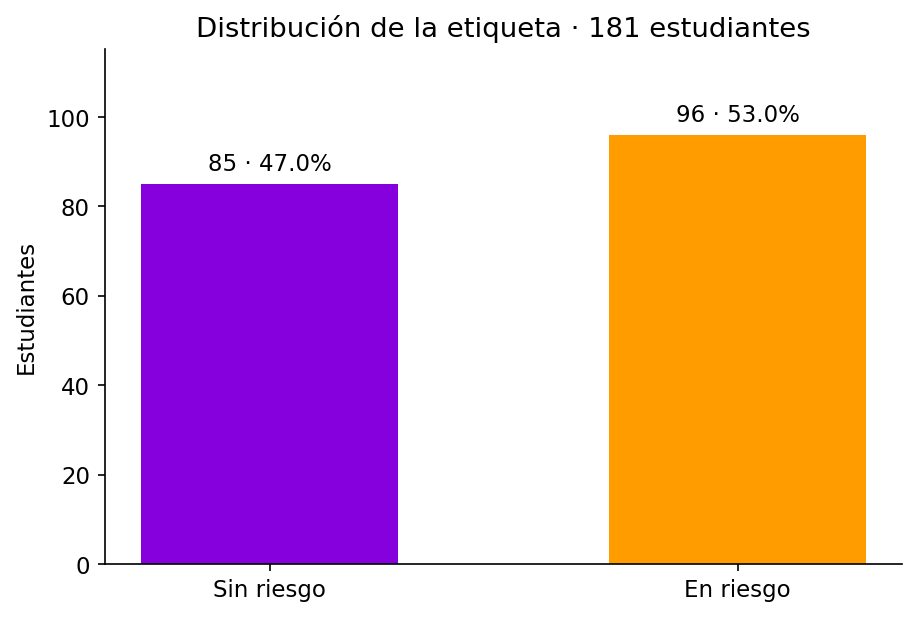

,Correlación
Promedio acumulado,-0.606
Brecha frente a los créditos esperados,0.425
Créditos aprobados por periodo cursado,-0.420
Cursos reprobados previos,0.379
Puntaje en la prueba diagnóstica del CCD,0.139
Cursos del CCD aprobados,0.025
Tendencia del promedio,0.007


In [3]:
display(Image(filename=str(FIGURAS / "distribucion_riesgo.png")))
corr = pd.Series(metricas["correlaciones_pearson"]["riesgo"], dtype=float).drop("riesgo")
display(corr.rename(index=NOMBRES).abs().sort_values(ascending=False).to_frame()
        .assign(Correlación=corr.rename(index=NOMBRES)).drop(columns=[0]).round(3))

## Comparación y evaluación

La partición estratificada reserva el 25 % para prueba. Se comparan regresión logística con estandarización y bosque aleatorio. Se elige por AUC promedio en cinco folds estratificados del conjunto de entrenamiento; si la logística queda a menos de 0,01 de AUC del mejor (diferencia menor que la desviación entre folds), se prefiere por ser interpretable (regla de parsimonia). Con ~135 casos de entrenamiento y 46 de prueba, las métricas de prueba tienen mucha varianza: el AUC de prueba (menor que el de validación cruzada) no indica sobreajuste grave, sino una muestra pequeña. Se muestran la dispersión entre folds y las métricas de prueba con umbral 0,50. En la matriz, las filas son las etiquetas observadas y las columnas son las predicciones. Un falso negativo es un caso de riesgo que el modelo omite a ese umbral.

Modelo elegido: Regresión logística
Estudiantes en entrenamiento: 135 · En prueba: 46


,AUC CV,DE AUC CV,AUC prueba,F1,Exactitud
Regresión logística,0.857,0.040,0.770,0.735,0.717
Bosque aleatorio,0.859,0.034,0.743,0.680,0.652


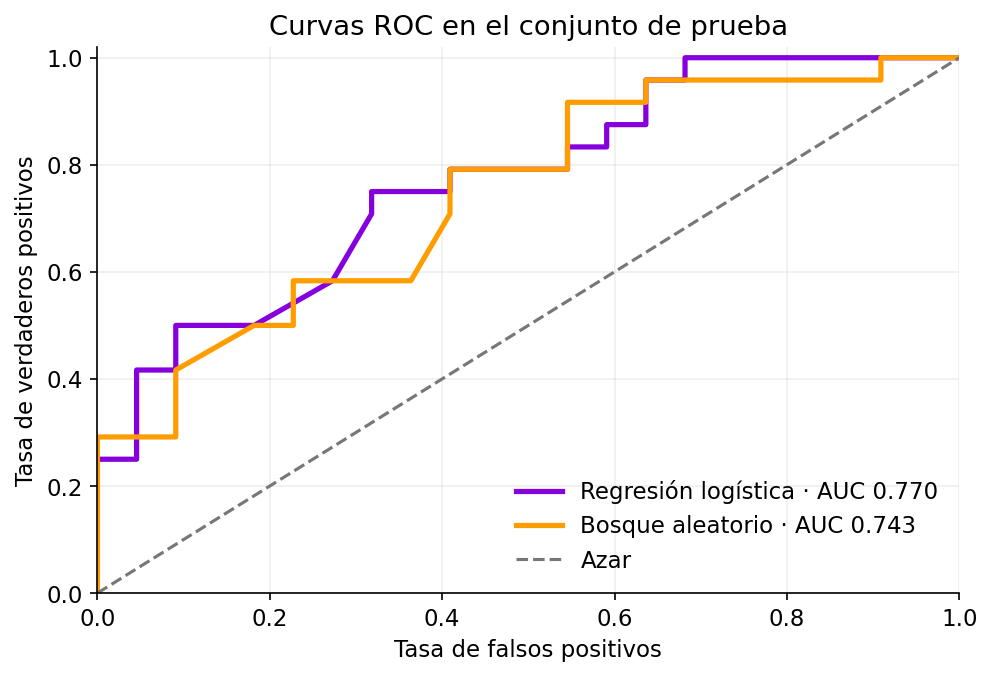

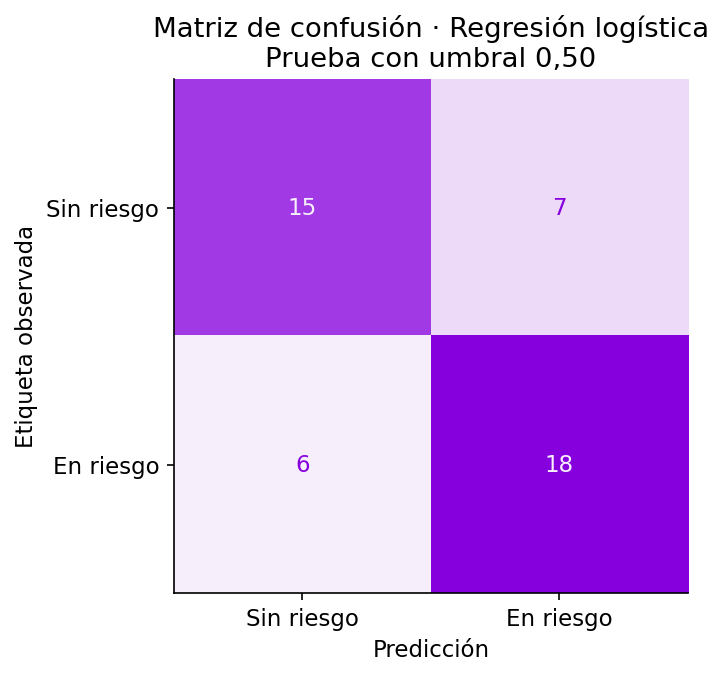

In [4]:
resultados = pd.DataFrame(metricas["modelos"]).T
columnas = {"auc_cv_media": "AUC CV", "auc_cv_desviacion": "DE AUC CV",
            "auc": "AUC prueba", "f1": "F1", "accuracy": "Exactitud"}
print(f"Modelo elegido: {metricas['modelo_elegido']}")
print(f"Estudiantes en entrenamiento: {metricas['n_train']} · En prueba: {metricas['n_test']}")
display(resultados[list(columnas)].rename(columns=columnas).astype(float).round(3))
for archivo in ("roc.png", "matriz_confusion.png"):
    display(Image(filename=str(FIGURAS / archivo)))

## Cómo leer el resultado individual

La logística organiza los factores por magnitud de coeficiente por valor estandarizado. Para la matrícula, usa el coeficiente del indicador activo. El signo expresa la dirección del aporte en la escala logarítmica de las razones de probabilidad. En el bosque, la permutación estima la caída de AUC al barajar una variable. Su aporte individual es la diferencia entre el puntaje observado y el calculado al sustituir solo esa variable por su mediana o estado más frecuente de entrenamiento.

Se publican hasta tres valores observados por estudiante, ordenados por magnitud del aporte. El nivel alto comienza en 0,60 y el medio en 0,35. Estos umbrales de la demo se aplican a la probabilidad guardada con cuatro decimales.

Coeficientes logísticos


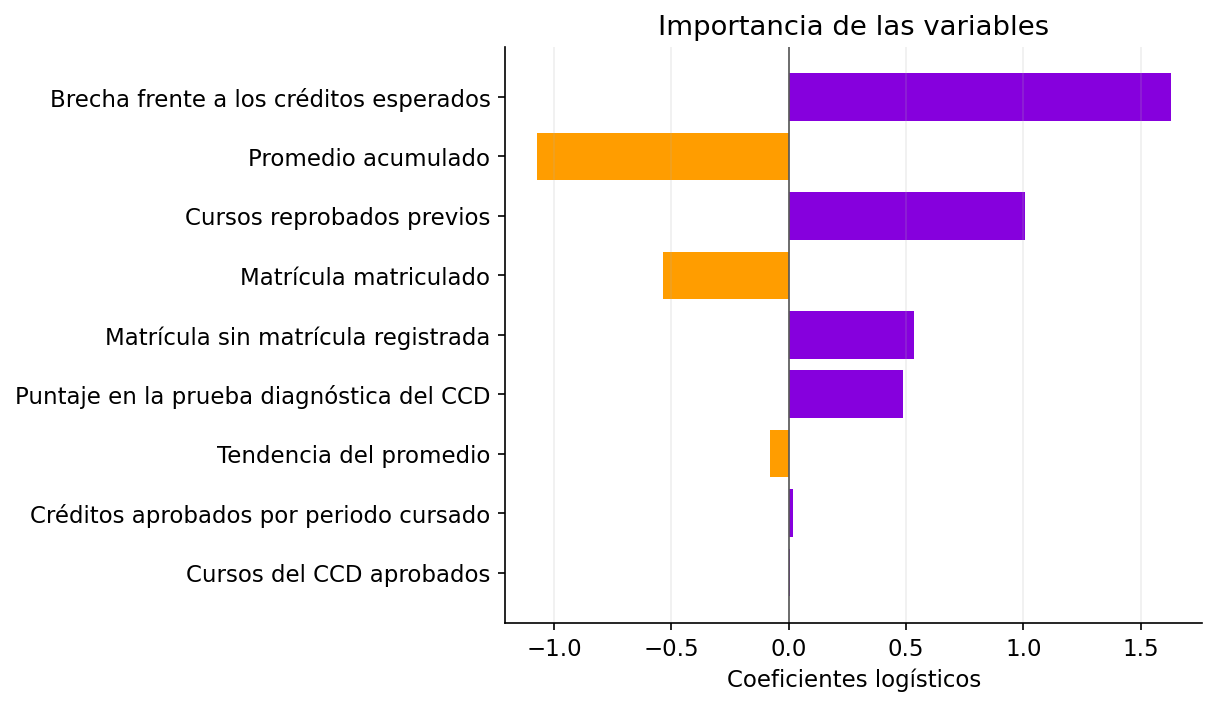

,Estudiantes por nivel
bajo,84
medio,36
alto,86


In [5]:
print(metricas["metodo_importancias"])
display(Image(filename=str(FIGURAS / "importancias.png")))
display(pd.Series(metricas["niveles"], name="Estudiantes por nivel").to_frame())

## Alcance y uso ético

Los resultados cuantifican qué tan bien los modelos aprenden patrones de las semillas sintéticas. La aptitud simulada genera dependencia entre los semestres y puede hacer que la validación parezca más favorable que en un despliegue real. La evaluación usa estudiantes distintos dentro de un mismo periodo sintético. Faltan pruebas en futuros periodos y en cada programa. Las probabilidades y los umbrales no se han calibrado para tomar decisiones institucionales.

La falta de notas o actividad digital puede reflejar cobertura de datos, modalidad, conectividad o características del programa. Antes de trabajar con datos reales se requeriría autorización institucional, revisión de sesgo por subgrupos, evaluación temporal y seguimiento de falsos positivos y falsos negativos.

En educación de precisión, la alerta puede abrir una conversación con el estudiante y orientar tutorías, recursos de estudio o acompañamiento. Su uso es orientativo y no punitivo. El acceso a cursos, becas o matrícula no debe depender del puntaje.